# Satellite image classification

AIM : Simple classifier model trained into satellite images for remote sensing,
current focus is purely for exploring tooling with CNN and transfer learning concept, current model might be only usefull into classifying images which it gets to work with, the domain itself contains a variety of problems to solve, such as image filteration, clearance and too advanced image segmentation which we might explore in future notebooks.

About dataset, it contains snapshots of different terrrain llike clouds, desert, green area, water bodies, which could be made together for a classifier to detect terrain information from image. with segmentation and advanced methods nothing can set the limmit.

### Transfer learning hands on with pytorch

Learning for making simple transfer learning based model with torch, taking pretrained model and fine tuning them for our own sparse small dataset, leveraging existing strong model from the pre-trained models.

**Transfer learning objective ( Loss function )**
+ Source domain dataset : $ x_s, x_t $
+ Target Domain dataset : $ x_t, y_t $
+ Neural network para   : $ f_{\theta} $
+ Feature representation: $ \phi(x) $
$$
L_{transfer} = L_{target}( f_{\phi}(x_t), y_t ) + \lambda * R(\phi)
$$

$ L_{target} $ : Loss function on target domain
$ R(\phi) $ : Regularization term for training 
$ \phi $ : Balance parameter between adaptation and preservation

Note : We are currently using predownloaded dataset, we could also build a data loader when building for server which sets up to download dataset from internet to train the model autonomously into the cloude,

In [1]:
# Libraries for deep neural construction
import torch
from torch import nn 

# vision utilities and pretrained models
import torchvision
from torchvision import transforms

# Data handle utilities
import matplotlib.pyplot as plt 
import pandas as pd 
import numpy as np 

# Keeping track of progress
from tqdm.auto import tqdm
from typing import Dict, List, Tuple

# system utilities
import os 
import requests
from pathlib import Path

device = 'cuda'

/home/madhav/workstation/Lab/experiment/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Axes: xlabel='label'>

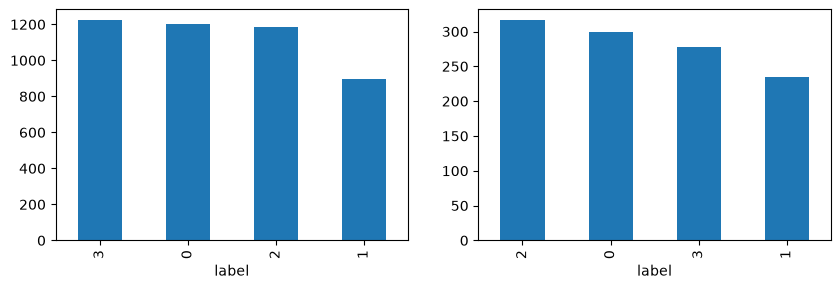

In [2]:
# Data statistics with the annotation file

an_df = pd.read_csv('/home/madhav/workstation/Lab/experiment/data/Satellite-Images/dataset_annotations.csv')

# Foundational statistics about class distribution in dataset
an_df['label'].value_counts() # Dataset is almost balanced with some small sample with desert

label_map = {name: i for i, name in enumerate(sorted(an_df['label'].unique()))}
an_df['label'] = an_df['label'].map(label_map)


# Standardize the weights
an_df['label'] = an_df['label'].astype('long')

# Train test split with the dataset
from sklearn.model_selection import train_test_split

train, test = train_test_split(an_df, test_size=0.2, random_state=41)

# trian test inspection for distribution
fig, axs = plt.subplots(1,2, figsize=(10,3))

train['label'].value_counts().plot(kind='bar', ax=axs[0])
test['label'].value_counts().plot(kind='bar', ax=axs[1])

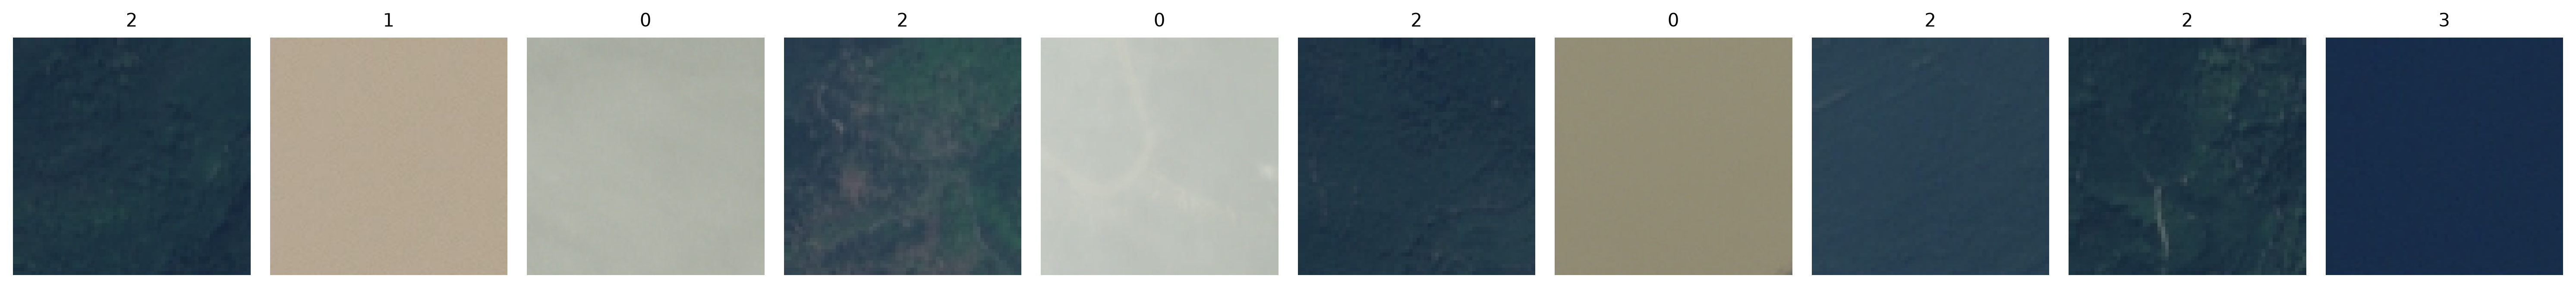

In [3]:
# Random visualization for the images
import random
from PIL import Image
import torch
import matplotlib.pyplot as plt
import pandas as pd

fig, axs = plt.subplots(1, 10, figsize=(20, 4), dpi=300)

sample = train.sample(10)

for i, row in enumerate(sample.itertuples()):
    path = row.image_path
    label = row.label

    image = Image.open(path).convert('RGB')
    axs[i].imshow(image)
    axs[i].set_title(label, fontsize=10) 
    axs[i].axis('off')

plt.tight_layout()
plt.show()


In [4]:
# Data preprocessing pipeline
from torchvision import transforms

''' 
creates a standardized transformation pipeline for transfer learning

Aimed for being simple transformation unit for efficient utilization from both source and transfer domain, 
for training the model.

Image net normalization parameter requirements
'''
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Simple pipeline composition with basic edits
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter( # color augmentation !! Might effect the most :)
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# With testing pipeline working for simple early transformation
test_transform = transforms.Compose(
    [
        transforms.Resize((224,224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN, std=IMAGENET_STD
        )
    ]
)

In [ ]:
# Data Loader utilities with torch
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
import torchvision.io as tv_io
from torchvision.io import ImageReadMode

class ImageDataset(Dataset):
    ''' 
    Simple image dataset object handle,
    Loading dataset through iamges pathways
    ''' 

    def __init__(self, dataframe, transform):
        
        self.image_paths = dataframe['image_path']
        self.labels = dataframe['label']
        self.transform = transform
    
    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths.iloc[idx,]

        image = Image.open(path).convert('RGB')
        transformed_tensor = self.transform(image)
        label = torch.tensor(self.labels.iloc[idx], dtype=torch.long)
                
        return transformed_tensor, label

# Dataset

# NOTE : Label must be set with numerical labling

train_dataset = ImageDataset(train, train_transform)
test_dataset = ImageDataset(test, test_transform)

train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=20,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=20,
    num_workers=2,
    pin_memory=True
)

# [NOTE] Need to read the documentation about the dataloader object here

In [6]:
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
print(weights)
model = torchvision.models.efficientnet_b0(weights=weights).to(device)

model

EfficientNet_B0_Weights.IMAGENET1K_V1


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          

In [7]:
# Transfer learning logic

# 1. Freez the main source model parameters | No training for them
for param in model.features.parameters():
    param.requires_grad = False

# 2. Editing the output layer the classifier part of the model
torch.manual_seed(42)
torch.cuda.manual_seed(42)

output_shape = len(train['label'].unique())

# 3. recreate the output layer | classification layer of the model
model.classifier = torch.nn.Sequential(
    torch.nn.Dropout(p=0.2, inplace=True),
    torch.nn.Linear(
        in_features=1280,
        out_features=output_shape,
        bias=True),
).to(device)

In [8]:
autotransform = weights.transforms()

In [9]:
# Training the Model

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def train_step(model, dataloader, loss_fn, optimizer, device):
    
    model.train()
    train_loss, train_acc = 0, 0

    # Loop through data loader for batches
    for batch, (X,y) in enumerate(dataloader):
        X = X.to(device)
        y = y.to(device)

        # Forward pass
        y_pred = model(X)
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()

        optimizer.step()

        # soft maxing for the whole batch size
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)

        # With simple boolean based logic for the prediction sumup 
        train_acc += (y_pred_class == y).sum().item() / len(y_pred)
    
    # Adjust the train loss 
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc

def test_step(model, dataloader, loss_fn, optimizer, device):
    model.eval()

    test_loss, test_acc = 0, 0
    with torch.inference_mode():
        for batch, (X,y) in enumerate(dataloader):
            X, y =  X.to(device), y.to(device)

            # Forward pass
            test_pred_logits = model(X)
            loss = loss_fn(test_pred_logits, y)
            test_loss  += loss.item()

            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((test_pred_labels == y).sum().item() / len(test_pred_labels))

    # Testing loss calculation
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc

In [10]:
# Main training loop

def train(model, train_dataloader, test_dataloader, loss_fn, optimizer, device):

    epotches = 10
    train_accs = []
    train_losses = []
    test_accs = []
    test_losses = []

    for epotch in tqdm(range(epotches)):
        
        train_loss, train_acc = train_step(model, train_dataloader, loss_fn, optimizer, device)
        test_loss, test_acc = test_step(model, test_dataloader, loss_fn, optimizer, device)

        train_accs.append(train_acc)
        train_losses.append(train_loss)

        test_accs.append(test_acc)
        test_losses.append(test_loss)
        print(f'With EPOTCH :{epotch} train acc : {train_acc} | test LOSS : {test_loss}')
        
    return train_accs, train_losses, test_accs, test_losses

In [ ]:
# Train execution

from timeit import default_timer as timer

start_stamp = timer()

# 💀 Dont un comment the below function or it would spin you laptop up right
# train(model, train_dataloader, test_dataloader, loss_fn, optimizer, device)

end_stamp = timer()

print(f'Time taken total : {end_stamp - start_stamp:.3f}')

  0%|          | 0/10 [00:00<?, ?it/s]

<PIL.Image.Image image mode=RGB size=64x64 at 0x70191FEFB860>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F74004D0>
<PIL.Image.Image image mode=RGB size=256x256 at 0x70191F1BDA30>
<PIL.Image.Image image mode=RGB size=256x256 at 0x70191F1BDA30>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8FCCD40>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018FB49A2A0>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8F3C410>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8FCCD40>
<PIL.Image.Image image mode=RGB size=64x64 at 0x70191F1BDA30>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8F4D220>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F7400230>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018FB49A2A0>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F7402B40>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8F4D220><PIL.Image.Image image mode=RGB size=64x64 at 0x7018F7403C80>

<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8

 10%|█         | 1/10 [00:24<03:43, 24.87s/it]

With EPOTCH :0 train acc : 0.885840707964602 | test LOSS : 0.20375821582580866
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DF3770>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8E454C0><PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8DF3770>

<PIL.Image.Image image mode=RGB size=256x256 at 0x70191FEFB860>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8D7F830>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DDF620>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F6159C10>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8D2A7E0>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F6159C70>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8DDF620>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8D28A70>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8DDDEB0>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DF35F0>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8D7F830>
<PIL.Image.Image image mode=RGB s

 20%|██        | 2/10 [00:51<03:29, 26.19s/it]

With EPOTCH :1 train acc : 0.931415929203539 | test LOSS : 0.14457986098632478
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DF3770>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8E454C0><PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DF3770>

<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8E1A570>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8E454C0>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8F2B080><PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DAD2B0>

<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DDF620><PIL.Image.Image image mode=RGB size=256x256 at 0x7018F6158590>

<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DDF740>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F6159C70>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DF3770>
<PIL.Image.Image image mode=RGB size=256x256 at 0x70191FEFB860>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F8F54B30>
<PIL.Image.Image image mode=RGB size=256x25

... (12 outputs left out)

 90%|█████████ | 9/10 [04:11<00:28, 28.38s/it]

With EPOTCH :8 train acc : 0.9553097345132736 | test LOSS : 0.0722754811051122
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F74BF620>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8D2A7E0>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F7421DC0>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8F2AA50><PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DDDEB0>

<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DDF740>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8DDDEB0>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8F56150><PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8F3D910>

<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F7402840>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F6238650>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F7402E10>
<PIL.Image.Image image mode=RGB size=64x64 at 0x7018F8F1A2A0>
<PIL.Image.Image image mode=RGB size=256x256 at 0x7018F7403BC0>
<PIL.Image.Image image mode=RGB size=256x256 at 0

100%|██████████| 10/10 [04:38<00:00, 27.86s/it]

With EPOTCH :9 train acc : 0.9513274336283185 | test LOSS : 0.07345971391585313
Time taken total : 278.645


In [12]:
# Saving the expensive trained model
import pickle

with open('model.pkl', 'wb') as f:
  pickle.dump(model, f)

In [23]:
label_map

{'cloudy': 0, 'desert': 1, 'green_area': 2, 'water': 3}

In [26]:

# # 1. Recreate the model architecture and load weights
# model = MyModelClass()
# model.load_state_dict(torch.load('model_weights.pth'))

model.eval()  # Set the model to evaluation mode (turns off dropout, batchnorm, etc.)


# 3. Load the image and run prediction
cloud_image = '/home/madhav/workstation/Lab/experiment/data/Satellite-Images/cloudy/train_26.jpg'
desert_image = '/home/madhav/workstation/Lab/experiment/data/Satellite-Images/desert/desert(2).jpg'
forest_image = '/home/madhav/workstation/Lab/experiment/data/Satellite-Images/green_area/Forest_5.jpg'
water_image = '/home/madhav/workstation/Lab/experiment/data/Satellite-Images/water/SeaLake_16.jpg'

img = Image.open(water_image).convert('RGB')

img_tensor = test_transform(img).unsqueeze(0)

img_tensor = img_tensor.to(device)

with torch.no_grad():  # Disable gradient calculation for faster inference
    output = model(img_tensor)
    
# Get the predicted class index
predicted_class = torch.argmax(output, dim=1).item()
print("Predicted Class Index:", predicted_class)


Predicted Class Index: 3
